# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/hotels.csv'

df = pd.read_csv(url)

display(df.head())
display(df.describe(include='all'))
df.info()

print("Missing values:")
print(df.isnull().sum())

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9404 entries, 0 to 9403
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           9404 non-null   object 
 1   is_canceled                     9404 non-null   int64  
 2   lead_time                       9404 non-null   int64  
 3   arrival_date_year               9404 non-null   int64  
 4   arrival_date_month              9404 non-null   object 
 5   arrival_date_week_number        9404 non-null   int64  
 6   arrival_date_day_of_month       9404 non-null   int64  
 7   stays_in_weekend_nights         9404 non-null   int64  
 8   stays_in_week_nights            9404 non-null   int64  
 9   adults                          9404 non-null   int64  
 10  children                        9404 non-null   int64  
 11  babies                          9404 non-null   int64  
 12  meal                            94

### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The dataset has a lot of information about hotel bookings, including prices, length of stays, and customer behavior. One thing that stands out is that some columns, like agent and company, have missing values. There are also bookings with very long lead times and unusual prices. These are things that should be considered before clustering.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [2]:
from sklearn.preprocessing import StandardScaler

# Remove duplicates
df = df.drop_duplicates().copy()

# Create total nights column
df['total_nights'] = (
    df['stays_in_weekend_nights'] +
    df['stays_in_week_nights']
)

# Select features
features = [
    'lead_time',
    'total_nights',
    'adr',
    'adults',
    'total_of_special_requests'
]

# Fix numeric data types
for col in features:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop missing values
df = df.dropna(subset=features)

# Remove unrealistic values and extreme outliers
df = df[
    df['lead_time'].between(0, 500) &
    df['total_nights'].between(1, 30) &
    df['adr'].between(1, 1000) &
    df['adults'].between(1, 5) &
    df['total_of_special_requests'].between(0, 5)
].copy()

df = df.reset_index(drop=True)

# Standardize features
scaler = StandardScaler()
X = scaler.fit_transform(df[features])

print("Cleaned rows:", len(df))
display(df[features].head())

Cleaned rows: 7510


,lead_time,total_nights,adr,adults,total_of_special_requests
0,7,1,75.0,1,0
1,13,1,75.0,1,0
2,14,2,98.0,2,1
3,0,2,107.0,2,0
4,9,2,103.0,2,1


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1.I selected lead time, total nights, average daily rate, adults, and special requests because they show different parts of customer booking behavior.

2. I expect to find groups like customers who book far in advance, customers who stay longer, and customers who spend more per night. These patterns could help hotels understand what different customers are looking for.



## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

KMeans Cluster Counts:
kmeans_cluster
0    1407
1    1884
2    1548
3    2671
Name: count, dtype: int64


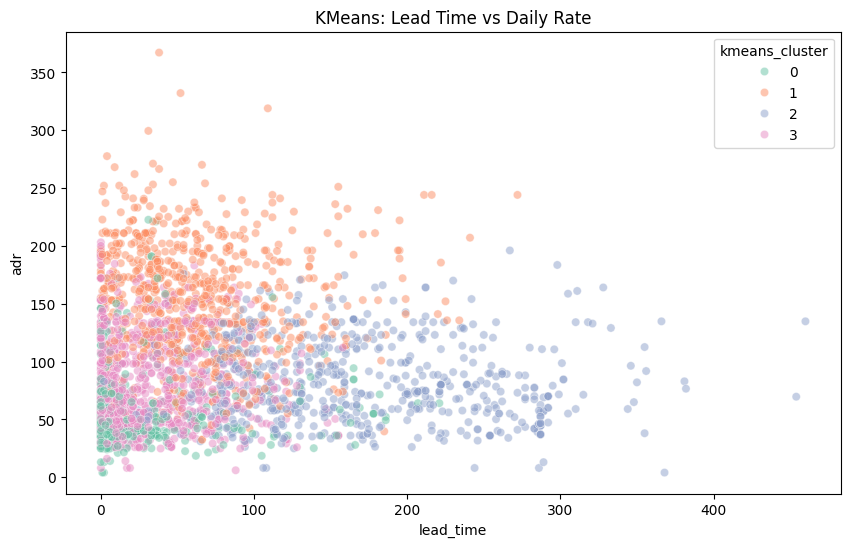

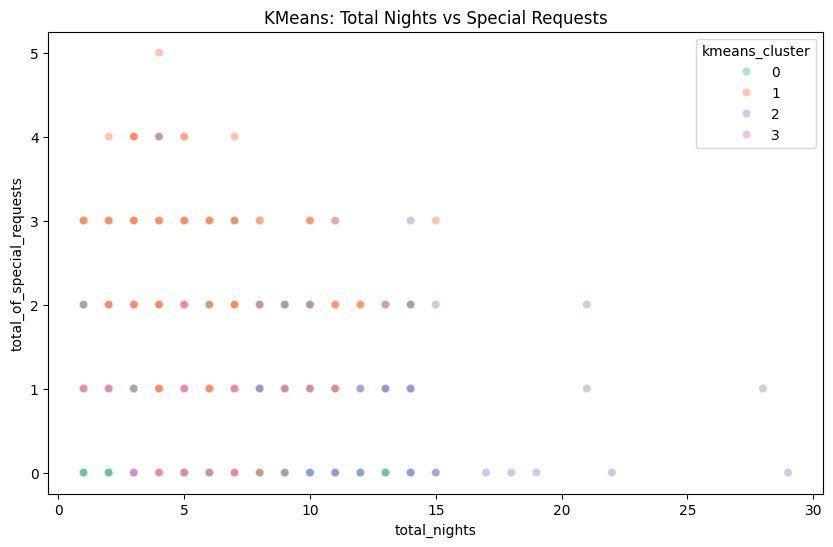

,lead_time,total_nights,adr,adults,total_of_special_requests
kmeans_cluster,,,,,
0,19.29,2.33,51.17,1.00,0.28
1,61.73,5.19,155.03,2.09,1.47
2,170.07,7.77,82.16,1.93,0.49
3,28.88,2.95,79.07,2.02,0.48


In [3]:
from sklearn.cluster import KMeans

# Fit KMeans model
kmeans = KMeans(n_clusters=4, random_state=1, n_init=10)

df['kmeans_cluster'] = kmeans.fit_predict(X)

print("KMeans Cluster Counts:")
print(df['kmeans_cluster'].value_counts().sort_index())

# Sample for visualization
plot_df = df.sample(n=min(3000, len(df)), random_state=1)

# Scatterplot 1
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x='lead_time',
    y='adr',
    hue='kmeans_cluster',
    palette='Set2',
    alpha=0.5
)
plt.title('KMeans: Lead Time vs Daily Rate')
plt.show()

# Scatterplot 2
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x='total_nights',
    y='total_of_special_requests',
    hue='kmeans_cluster',
    palette='Set2',
    alpha=0.5
)
plt.title('KMeans: Total Nights vs Special Requests')
plt.show()

# Cluster averages
kmeans_summary = df.groupby('kmeans_cluster')[features].mean().round(2)

display(kmeans_summary)

### Reflection:
1. What `k` value did you choose, and how did you decide?

2. For each cluster answer the following - what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
I chose 4 clusters because it gave a good balance between finding different customer groups and keeping the results easy to understand.

Cluster 0 (1,407 bookings): These customers book about 19 days ahead, stay around 2 nights, and spend about $51 per night. They seem like budget travelers taking short trips.

Cluster 1 (1,884 bookings): These customers spend the most at around $155 per night and make the most special requests. They seem like higher-spending guests who expect more services.

Cluster 2 (1,548 bookings): These customers book the farthest in advance at around 170 days and stay the longest at nearly 8 nights. They seem like people planning longer vacations ahead of time.

Cluster 3 (2,671 bookings): These customers book about 29 days ahead, stay around 3 nights, and spend about $79 per night. They seem like typical short-stay travelers who want affordable accommodations.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

GMM Cluster Counts:
gmm_cluster
0     868
1     269
2     689
3    5684
Name: count, dtype: int64
Average Assignment Confidence:
0.996


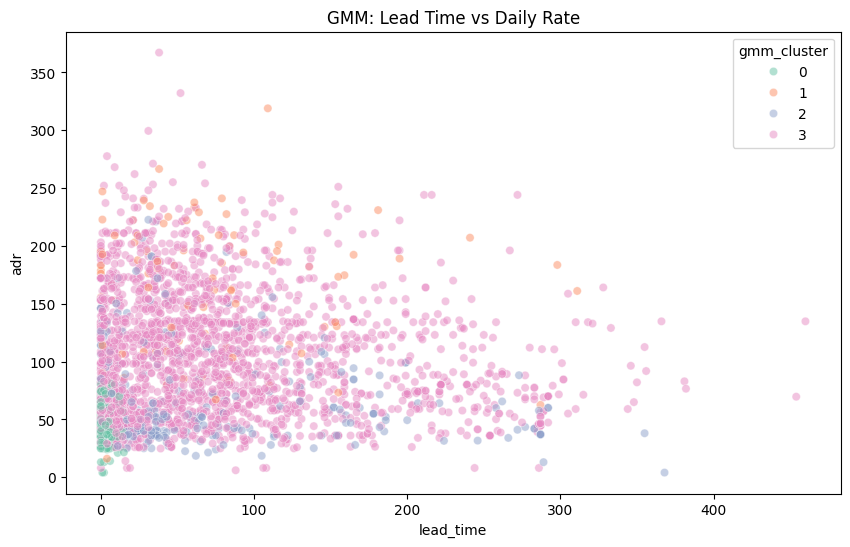

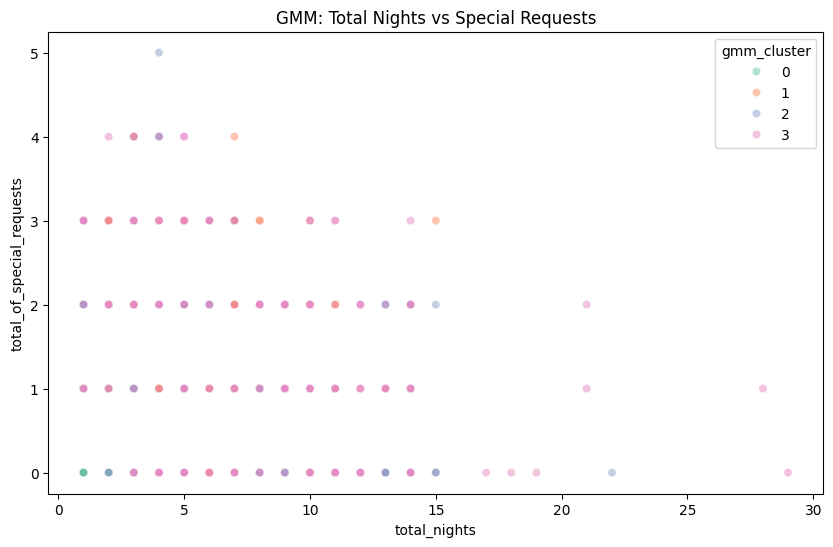

,lead_time,total_nights,adr,adults,total_of_special_requests
gmm_cluster,,,,,
0,2.67,1.43,41.23,1.00,0.17
1,72.46,5.27,153.28,3.03,1.04
2,75.07,4.71,67.54,1.00,0.57
3,72.19,4.76,101.85,2.00,0.77


In [4]:
from sklearn.mixture import GaussianMixture

# Fit GMM with 4 clusters
gmm = GaussianMixture(
    n_components=4,
    covariance_type='diag',
    random_state=1,
    n_init=2,
    reg_covar=1e-5
)

gmm.fit(X)

# Get probabilities and cluster assignments
gmm_probabilities = gmm.predict_proba(X)
df['gmm_cluster'] = gmm_probabilities.argmax(axis=1)

df['gmm_confidence'] = gmm_probabilities.max(axis=1)

print("GMM Cluster Counts:")
print(df['gmm_cluster'].value_counts().sort_index())

print("Average Assignment Confidence:")
print(df['gmm_confidence'].mean().round(3))

# Sample for visualization
plot_df = df.sample(n=min(3000, len(df)), random_state=1)

# Scatterplot 1
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x='lead_time',
    y='adr',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.5
)
plt.title('GMM: Lead Time vs Daily Rate')
plt.show()

# Scatterplot 2
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=plot_df,
    x='total_nights',
    y='total_of_special_requests',
    hue='gmm_cluster',
    palette='Set2',
    alpha=0.5
)
plt.title('GMM: Total Nights vs Special Requests')
plt.show()

# GMM summary
gmm_summary = df.groupby('gmm_cluster')[features].mean().round(2)

display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. The GMM results were different from KMeans because GMM placed most customers into one large cluster, while KMeans divided them more evenly. GMM also identified smaller groups, like customers booking very short stays and customers traveling with more adults. The average assignment confidence was 99.6%, showing that the model was very confident in its group assignments.

2. GMM could help hotels figure out which customers might fit into multiple groups and which promotions would work best for them. For example, a customer might be interested in both longer-stay discounts and premium room offers. This could help hotels personalize their marketing instead of sending everyone the same offers.



## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [5]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Use a random sample for evaluation
rng = np.random.default_rng(1)
sample_idx = rng.choice(
    len(X),
    size=min(3000, len(X)),
    replace=False
)

X_sample = X[sample_idx]

# KMeans labels
km_labels = df['kmeans_cluster'].to_numpy()
gmm_labels = df['gmm_cluster'].to_numpy()

# WCSS
km_wcss = kmeans.inertia_

# GMM WCSS based on hard cluster assignments
gmm_centers = np.array([
    X[gmm_labels == i].mean(axis=0)
    for i in range(4)
])

gmm_wcss = np.sum(
    (X - gmm_centers[gmm_labels]) ** 2
)

# Evaluation table
results = pd.DataFrame({
    'Model': ['KMeans', 'GMM'],
    'WCSS': [km_wcss, gmm_wcss],
    'Silhouette Score': [
        silhouette_score(X_sample, km_labels[sample_idx]),
        silhouette_score(X_sample, gmm_labels[sample_idx])
    ],
    'Davies-Bouldin Index': [
        davies_bouldin_score(X, km_labels),
        davies_bouldin_score(X, gmm_labels)
    ]
})

display(results.round(3))

,Model,WCSS,Silhouette Score,Davies-Bouldin Index
0,KMeans,19260.142,0.275,1.349
1,GMM,26733.463,0.207,1.581


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. KMeans performed better on all three metrics. It had a lower WCSS of 19,260 compared to GMM's 26,733. KMeans also had a higher Silhouette Score of 0.275 compared to 0.207 and a lower Davies-Bouldin Index of 1.349 compared to 1.581. This shows that KMeans created tighter and more separated clusters.

5.3. I would recommend KMeans because it performed better on all three metrics and divided the customers into more balanced groups. It is also easier to understand and explain to managers. For a hotel trying to target different types of customers with promotions, KMeans would be more useful because the groups are easier to identify and compare.


## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [7]:
# Show cluster characteristics
cluster_summary = df.groupby('kmeans_cluster').agg(
    bookings=('lead_time', 'size'),
    avg_lead_time=('lead_time', 'mean'),
    avg_nights=('total_nights', 'mean'),
    avg_daily_rate=('adr', 'mean'),
    avg_adults=('adults', 'mean'),
    avg_special_requests=('total_of_special_requests', 'mean')
)

# Sort by average daily rate
cluster_summary = cluster_summary.sort_values('avg_daily_rate')

display(cluster_summary.round(2))

,bookings,avg_lead_time,avg_nights,avg_daily_rate,avg_adults,avg_special_requests
kmeans_cluster,,,,,,
0,1407,19.29,2.33,51.17,1.00,0.28
3,2671,28.88,2.95,79.07,2.02,0.48
2,1548,170.07,7.77,82.16,1.93,0.49
1,1884,61.73,5.19,155.03,2.09,1.47


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1. The four clusters represent different types of hotel guests. Cluster 0 includes budget travelers who book close to their stay and spend about $51 per night. Cluster 1 includes higher-spending guests who make more special requests. Cluster 2 includes guests who book far in advance and stay longer, averaging almost 8 nights. Cluster 3 includes typical short-stay travelers who spend around $79 per night.

2. The hotel could offer budget deals and last-minute discounts to Cluster 0. Cluster 1 could receive premium room upgrades and personalized services since they spend more and make more requests. Cluster 2 could be targeted with early booking discounts and extended-stay packages. Cluster 3 could receive weekend getaway deals or promotions for shorter stays.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The most challenging part was understanding what the clusters actually meant. Since there are no labels, I had to compare the averages and look at the graphs to figure out what made each group different.

2. I would use clustering when I want to find patterns in data without already knowing the categories. Supervised models are better when there is a specific outcome to predict, like whether a customer will cancel a reservation.

3. I would explain that clustering helps businesses group similar customers together. This makes it easier to understand customer behavior and create marketing strategies that target different types of customers.

4. This assignment helped me practice using Python to analyze real business data and turn the results into useful insights. It also showed me how data analytics can help businesses make better decisions about marketing and customer behavior.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [ ]:
!jupyter nbconvert --to html "assignment_09_clustering.ipynb"